[Python, Visually](https://johnfisher-ai.github.io/Python-Visual-Guides/) &nbsp;&rsaquo;&nbsp; [GeoPandas, Deep Dive](https://johnfisher-ai.github.io/Python-Visual-Guides/geopandas-deep-dive.html)

# Making Maps &middot; Solutions


One way to do each task. Not the only way. If yours runs and does what was asked, yours is
right too.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd
import shapely
import mapclassify
import matplotlib.pyplot as plt

COUNTRIES_URL = ("https://raw.githubusercontent.com/johnfisher-ai/Python-Visual-Guides/main/data/nordic-countries.geojson")
local_copy = Path("../../data/nordic-countries.geojson")
countries = gpd.read_file(local_copy if local_copy.exists() else COUNTRIES_URL)


weather_stations = pd.DataFrame({
    "name": ["Bergen", "Oslo", "Svalbard", "Tromso", "Kirkenes"],
    "latitude": [60.39, 59.91, 78.22, 69.65, 69.73],
    "longitude": [5.32, 10.75, 15.65, 18.96, 30.05],
})


def mainland_norway():
    """Norway's outline south of 74 degrees north, without Svalbard, in UTM zone 33N."""
    parts = countries[countries["ADMIN"] == "Norway"].to_crs(25833).explode()
    return parts[parts.geometry.bounds["maxy"] < 8_200_000].union_all()


def station_network(n=300, seed=2026):
    """A made-up register of weather stations on mainland Norway, one row each."""
    rng = np.random.default_rng(seed)
    land = mainland_norway()
    x_min, y_min, x_max, y_max = land.bounds
    east, north = [], []
    while len(east) < n:
        x, y = rng.uniform(x_min, x_max), rng.uniform(y_min, y_max)
        if land.contains(shapely.Point(x, y)):
            east.append(x)
            north.append(y)
    lonlat = gpd.GeoSeries(gpd.points_from_xy(east, north), crs=25833).to_crs(4326)
    return pd.DataFrame({
        "station": [f"NS{i:03d}" for i in range(1, n + 1)],
        "latitude": lonlat.y.round(4).to_numpy(), "longitude": lonlat.x.round(4).to_numpy(),
        "elevation_m": np.clip(rng.gamma(1.6, 220, n), 2, 1900).round(0).astype(int),
        "owner": rng.choice(["met", "road", "airport", "private"], n, p=[0.4, 0.3, 0.1, 0.2]),
        "installed": rng.integers(1950, 2025, n),
    })


DISTRICT_CENTERS = {"South": (8.0, 58.6), "East": (10.8, 60.5), "West": (6.0, 60.8), "Mid": (11.0, 63.6),
                    "North": (14.5, 67.0), "Far North": (19.0, 69.4), "Northeast": (25.5, 70.0),
                    "Svalbard": (16.0, 78.5)}


def forecast_districts():
    """Eight made-up forecast districts that cover Norway, in UTM zone 33N."""
    norway = countries[countries["ADMIN"] == "Norway"].to_crs(25833).geometry.iloc[0]
    centers = gpd.GeoSeries(gpd.points_from_xy(*zip(*DISTRICT_CENTERS.values())), crs=4326).to_crs(25833)
    cells = shapely.voronoi_polygons(shapely.MultiPoint(list(centers)),
                                     extend_to=shapely.box(*norway.buffer(200_000).bounds)).geoms
    names = [next(name for name, center in zip(DISTRICT_CENTERS, centers) if cell.contains(center))
             for cell in cells]
    districts = gpd.GeoDataFrame({"district": names}, geometry=[cell.intersection(norway) for cell in cells],
                                 crs=25833)
    return districts.set_index("district").loc[list(DISTRICT_CENTERS)].reset_index()


network = station_network()
stations = gpd.GeoDataFrame(
    network, geometry=gpd.points_from_xy(network["longitude"], network["latitude"]), crs=4326
)


named = gpd.GeoDataFrame(
    weather_stations,
    geometry=gpd.points_from_xy(weather_stations["longitude"], weather_stations["latitude"]),
    crs=4326,
)

districts = forecast_districts()
print("geopandas", gpd.__version__, "| mapclassify", mapclassify.__version__, "|", len(countries), "countries,",
      len(stations), "made-up stations,", len(districts), "made-up districts")

geopandas 1.2.0 | mapclassify 2.10.0 | 5 countries, 300 made-up stations, 8 made-up districts


The worked examples' layers and densities, rebuilt here from the made-up stations and districts so that each answer runs on its own.

In [2]:
countries_m = countries.to_crs(25833)
stations_m = stations.to_crs(25833)
named_m = named.to_crs(25833)
placed = gpd.sjoin(stations_m, districts, how="left")
counts = placed.groupby("district").size().reindex(districts["district"], fill_value=0)
density = districts.assign(stations=counts.to_numpy())
density["per_10k_km2"] = (density["stations"] / (density.area / 1e6) * 10_000).round(1)

**1.** Draw the countries in UTM zone 33N colored by `POP_EST`, with `scheme="Quantiles"`, `k=3` and a legend.

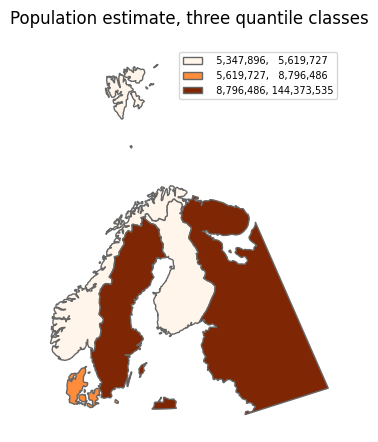

In [3]:
fig, ax = plt.subplots(figsize=(6, 5))
countries_m.plot(ax=ax, column="POP_EST", scheme="Quantiles", k=3, cmap="Oranges", edgecolor="0.4",
                 legend=True, legend_kwds={"loc": "upper right", "fontsize": 7, "fmt": "{:,.0f}"})
ax.set_axis_off()
ax.set_title("Population estimate, three quantile classes")
plt.show()

Five countries in three classes gives two, one and two to a class, with Russia in the top class. The population is Natural Earth's estimate for the whole country, while the outline of Russia is cut at 42 degrees east.

**2.** Draw the network stations colored by the year they were installed, in four equal-interval classes, over the countries in gray.

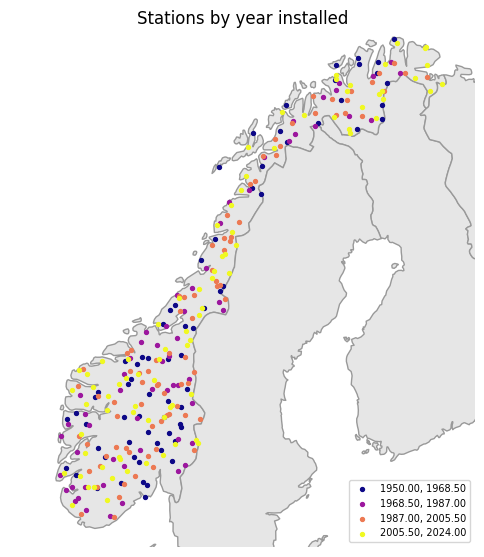

In [4]:
fig, ax = plt.subplots(figsize=(6, 7))
countries_m.plot(ax=ax, color="0.9", edgecolor="0.6")
stations_m.plot(ax=ax, column="installed", scheme="EqualInterval", k=4, cmap="plasma", markersize=8,
                legend=True, legend_kwds={"loc": "lower right", "fontsize": 7})
ax.set_xlim(-200_000, 1_200_000)
ax.set_ylim(6_400_000, 7_950_000)
ax.set_axis_off()
ax.set_title("Stations by year installed")
plt.show()

A scheme works on points as it does on polygons. Equal intervals split the years from 1950 to 2024 into four steps of about 18 years.

**3.** Draw a map of the Northeast district with its stations colored by owner, and Kirkenes as a black triangle.

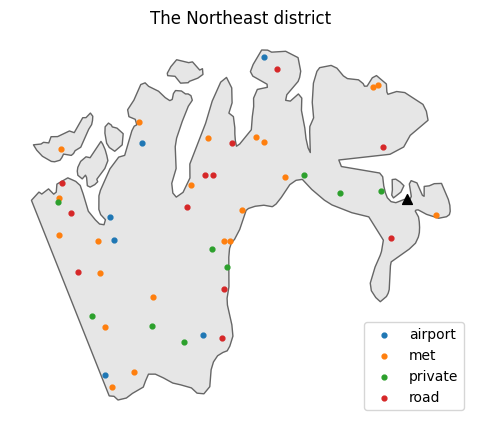

In [5]:
northeast = districts[districts["district"] == "Northeast"]
fig, ax = plt.subplots(figsize=(6, 5))
northeast.plot(ax=ax, color="0.9", edgecolor="0.4")
placed[placed["district"] == "Northeast"].plot(ax=ax, column="owner", categorical=True, markersize=12,
                                               legend=True, legend_kwds={"loc": "lower right"})
named_m[named_m["name"] == "Kirkenes"].plot(ax=ax, color="black", marker="^", markersize=50)
ax.set_axis_off()
ax.set_title("The Northeast district")
plt.show()

Kirkenes stands on the coast, and the 1:50m outline puts its point just outside the district's polygon.

**4.** Print the class that `mapclassify.Quantiles` with `k=4` gives each district's density, beside the district's name.

In [6]:
classes = mapclassify.Quantiles(density["per_10k_km2"], k=4)
print(classes.bins.round(2).tolist())
density.assign(quantile_class=classes.yb)[["district", "per_10k_km2", "quantile_class"]]

[8.0, 8.8, 9.22, 11.2]


,district,per_10k_km2,quantile_class
0,South,8.9,2
1,East,9.0,2
2,West,8.0,0
3,Mid,11.2,3
4,North,8.7,1
5,Far North,8.0,0
6,Northeast,9.9,3
7,Svalbard,0.0,0


Class 0 holds the lowest values. West and Far North tie at 8.0, which is also the first class's upper edge, so the first class holds them and Svalbard, and the second holds North alone.

**5.** Draw the districts in latitude and longitude, EPSG:4326, beside the same districts in UTM zone 33N, and print how much GeoPandas stretched the axes of the first.

stretch in degrees: 2.82


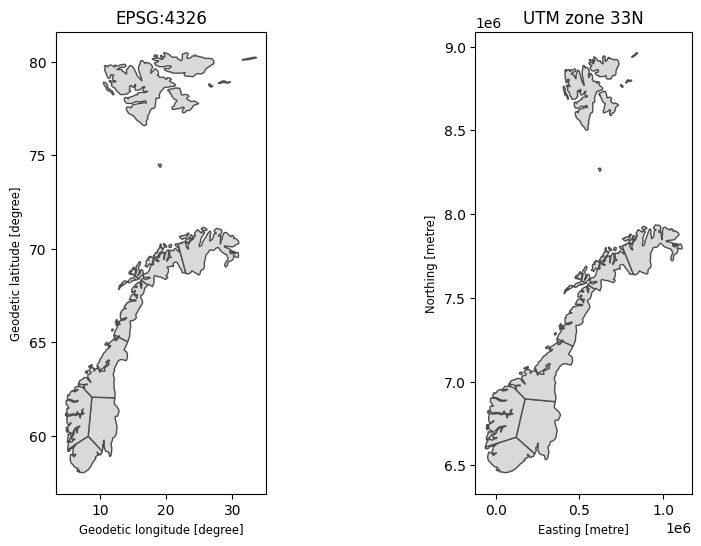

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 6))
districts.to_crs(4326).plot(ax=axes[0], color="0.85", edgecolor="0.3")
axes[0].set_title("EPSG:4326")
districts.plot(ax=axes[1], color="0.85", edgecolor="0.3")
axes[1].set_title("UTM zone 33N")
print("stretch in degrees:", round(axes[0].get_aspect(), 2))
plt.show()

The districts reach from 58.0 to 80.5 degrees north, and a stretch of 2.82 is right at about 69 degrees, near the middle of that range, so Svalbard is drawn wider than in UTM.

---

&#8592; **Back to:** [Making Maps](https://colab.research.google.com/github/johnfisher-ai/Python-Visual-Guides/blob/main/notebooks/geopandas-deep-dive/12-making-maps.ipynb)  &nbsp;&middot;&nbsp;  [GeoPandas, Deep Dive Notebooks](https://johnfisher-ai.github.io/Python-Visual-Guides/geopandas-deep-dive.html)
